# 📐 Statistical Analysis & Predictive Modeling

**Objective**: Apply statistical tests to validate operational hypotheses and build predictive models for delivery risk and revenue forecasting.

**Author**: Sharan Biradar  
**Date**: October 2026

### Tests Performed
1. ANOVA — Delivery days differ significantly across regions?
2. Chi-Square — Is late delivery independent of product category?
3. Pearson Correlation — Discount rate vs profit margin relationship
4. Linear Regression — Predict lost sales from operational factors
5. Time Series Decomposition — Revenue trend & seasonality

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Load and prepare data
excel_path = '../operational_intelligence_dataset.xlsx'
sales = pd.read_excel(excel_path, sheet_name='Sales_Fact')
products = pd.read_excel(excel_path, sheet_name='Product_Dim')
customers = pd.read_excel(excel_path, sheet_name='Customer_Dim')
warehouses = pd.read_excel(excel_path, sheet_name='Warehouse_Dim')

df = (sales.merge(products, on='Product_ID', how='left')
      .merge(customers, on='Customer_ID', how='left')
      .merge(warehouses, on='Warehouse_ID', how='left', suffixes=('', '_wh')))

df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Month'] = df['Order_Date'].dt.month
print(f'✅ Data loaded: {df.shape[0]} rows × {df.shape[1]} columns')

✅ Data loaded: 500 rows × 31 columns


---
## Test 1: One-Way ANOVA — Delivery Days Across Regions

**Hypothesis**:  
- H₀: Mean delivery days are the same across all 4 regions  
- H₁: At least one region has a significantly different mean delivery time  
- Significance level: α = 0.05

🧪 ONE-WAY ANOVA: Delivery Days by Region
F-statistic: 0.3147
P-value:     0.814769
α = 0.05

Result: FAIL TO REJECT H₀
→ No significant difference in delivery times across regions.

📊 Regional Delivery Days Summary:


,mean,std,median,count
Region,,,,
East,3.52,1.41,4.0,105
North,3.66,1.41,4.0,107
South,3.64,1.43,4.0,131
West,3.54,1.24,4.0,157


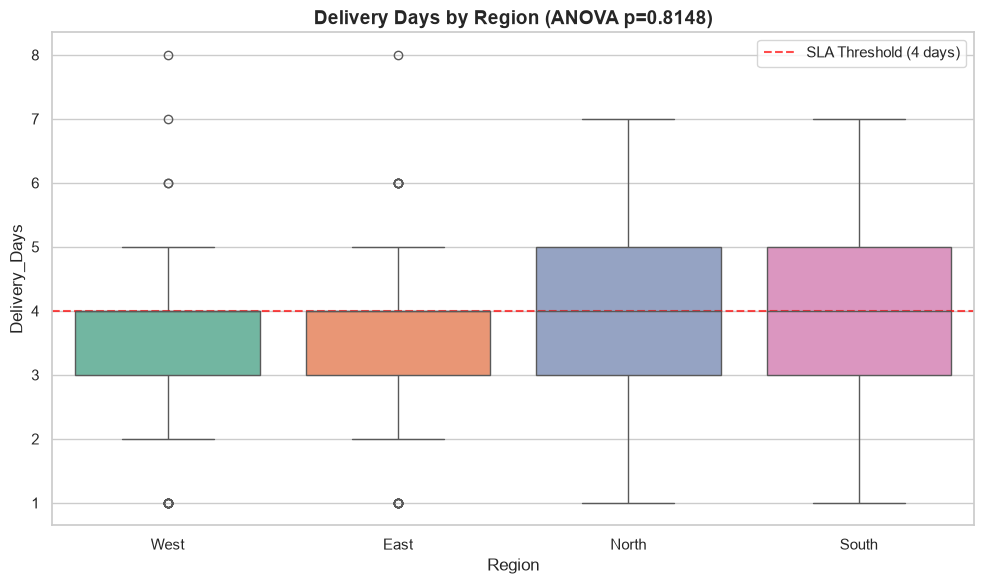

In [2]:
# Group delivery days by region
regions = df['Region'].unique()
region_groups = [df[df['Region'] == r]['Delivery_Days'].values for r in regions]

# Perform one-way ANOVA
f_stat, p_value = stats.f_oneway(*region_groups)

print('🧪 ONE-WAY ANOVA: Delivery Days by Region')
print('=' * 50)
print(f'F-statistic: {f_stat:.4f}')
print(f'P-value:     {p_value:.6f}')
print(f'α = 0.05')
print(f'\nResult: {"REJECT H₀" if p_value < 0.05 else "FAIL TO REJECT H₀"}')
if p_value < 0.05:
    print('→ Delivery times differ SIGNIFICANTLY across regions.')
else:
    print('→ No significant difference in delivery times across regions.')

# Regional summary
print(f'\n📊 Regional Delivery Days Summary:')
regional_stats = df.groupby('Region')['Delivery_Days'].agg(['mean', 'std', 'median', 'count'])
display(regional_stats.round(2))

# Box plot visualization
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df, x='Region', y='Delivery_Days', palette='Set2', ax=ax)
ax.axhline(y=4, color='red', linestyle='--', alpha=0.7, label='SLA Threshold (4 days)')
ax.set_title(f'Delivery Days by Region (ANOVA p={p_value:.4f})', fontsize=14, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/anova_delivery_days.png', dpi=150, bbox_inches='tight')
plt.show()

# Post-hoc: Tukey HSD (if ANOVA is significant)
if p_value < 0.05:
    from scipy.stats import mannwhitneyu
    print('\n📊 Post-hoc Pairwise Comparisons (Mann-Whitney U):')
    for i in range(len(regions)):
        for j in range(i+1, len(regions)):
            stat, p = mannwhitneyu(region_groups[i], region_groups[j], alternative='two-sided')
            sig = '✅ Significant' if p < 0.05 else '❌ Not significant'
            print(f'  {regions[i]} vs {regions[j]}: U={stat:.1f}, p={p:.4f} → {sig}')

---
## Test 2: Chi-Square Test — Late Delivery vs Product Category

**Hypothesis**:  
- H₀: Late delivery is independent of product category  
- H₁: Late delivery is associated with product category  
- Significance level: α = 0.05

In [3]:
# Create contingency table
contingency = pd.crosstab(df['Product_Category'], df['Delivery_Status'])
print('📊 Contingency Table:')
display(contingency)

# Chi-Square test
chi2, p_value, dof, expected = stats.chi2_contingency(contingency)

print(f'\n🧪 CHI-SQUARE TEST: Late Delivery vs Product Category')
print('=' * 50)
print(f'Chi² statistic: {chi2:.4f}')
print(f'P-value:        {p_value:.6f}')
print(f'Degrees of freedom: {dof}')
print(f'\nResult: {"REJECT H₀" if p_value < 0.05 else "FAIL TO REJECT H₀"}')
if p_value < 0.05:
    print('→ Late delivery IS associated with product category.')
else:
    print('→ Late delivery is INDEPENDENT of product category (no association).')

# Late rate by category
late_by_cat = (df.groupby('Product_Category')['Delivery_Status']
               .apply(lambda x: (x == 'Late').mean() * 100)
               .sort_values(ascending=False))
print(f'\n📊 Late Delivery Rate by Category:')
for cat, rate in late_by_cat.items():
    print(f'  {cat:20s}: {rate:.1f}%')

📊 Contingency Table:


Delivery_Status,Late,On Time
Product_Category,,
Accessories,11,40
Bundles,4,13
Cigarettes,35,112
Heat-Not-Burn,25,62
Merchandising,3,11
Oral Nicotine,17,52
Vapes,32,83



🧪 CHI-SQUARE TEST: Late Delivery vs Product Category
Chi² statistic: 1.6285
P-value:        0.950505
Degrees of freedom: 6

Result: FAIL TO REJECT H₀
→ Late delivery is INDEPENDENT of product category (no association).

📊 Late Delivery Rate by Category:
  Heat-Not-Burn       : 28.7%
  Vapes               : 27.8%
  Oral Nicotine       : 24.6%
  Cigarettes          : 23.8%
  Bundles             : 23.5%
  Accessories         : 21.6%
  Merchandising       : 21.4%


---
## Test 3: Correlation — Discount Rate vs Profit Margin

**Question**: Does offering higher discounts erode profit margins?

🧪 PEARSON CORRELATION: Discount % vs Profit Margin %
Correlation (r): -0.3769
P-value:         0.000000
R² (explained):  0.1421

Interpretation: Moderate negative correlation
→ The relationship IS statistically significant.


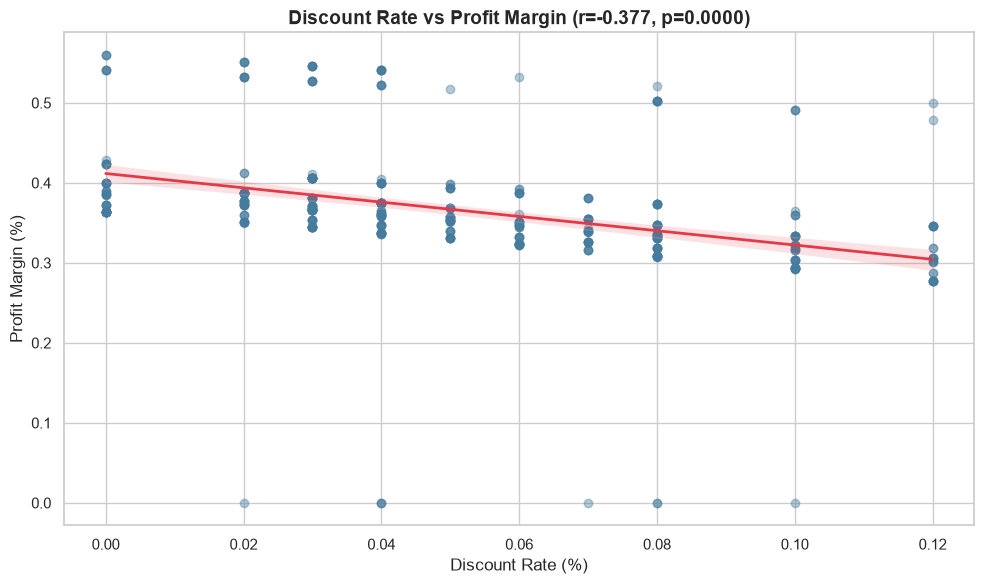

In [4]:
# Pearson correlation
r, p_value = stats.pearsonr(df['Discount_Pct'], df['Profit_Margin_Pct'])

print('🧪 PEARSON CORRELATION: Discount % vs Profit Margin %')
print('=' * 50)
print(f'Correlation (r): {r:.4f}')
print(f'P-value:         {p_value:.6f}')
print(f'R² (explained):  {r**2:.4f}')
print(f'\nInterpretation: {"Strong" if abs(r) > 0.5 else "Moderate" if abs(r) > 0.3 else "Weak"} '
      f'{"negative" if r < 0 else "positive"} correlation')
if p_value < 0.05:
    print(f'→ The relationship IS statistically significant.')
else:
    print(f'→ The relationship is NOT statistically significant.')

# Scatter plot
fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=df, x='Discount_Pct', y='Profit_Margin_Pct',
            scatter_kws={'alpha': 0.4, 'color': '#457B9D'},
            line_kws={'color': '#E63946', 'linewidth': 2}, ax=ax)
ax.set_title(f'Discount Rate vs Profit Margin (r={r:.3f}, p={p_value:.4f})',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Discount Rate (%)')
ax.set_ylabel('Profit Margin (%)')
plt.tight_layout()
plt.savefig('../reports/figures/discount_vs_margin.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Test 4: Linear Regression — Predicting Lost Sales

**Objective**: Build a model to predict `Lost_Sales_Estimate` from operational factors.

🤖 LINEAR REGRESSION: Predicting Lost Sales
R² Score:            0.1885
Mean Absolute Error: $75.75
RMSE:                $110.60

📊 Feature Importance (by coefficient magnitude):


,Feature,Coefficient
1,Discount_Pct,1658.9271
7,Segment_Encoded,-37.3811
6,Category_Encoded,15.7474
5,Region_Encoded,11.7926
2,Delivery_Days,5.5992
0,Quantity,-3.3130
4,Reorder_Level,1.9949
3,Stock_On_Hand,-1.1315


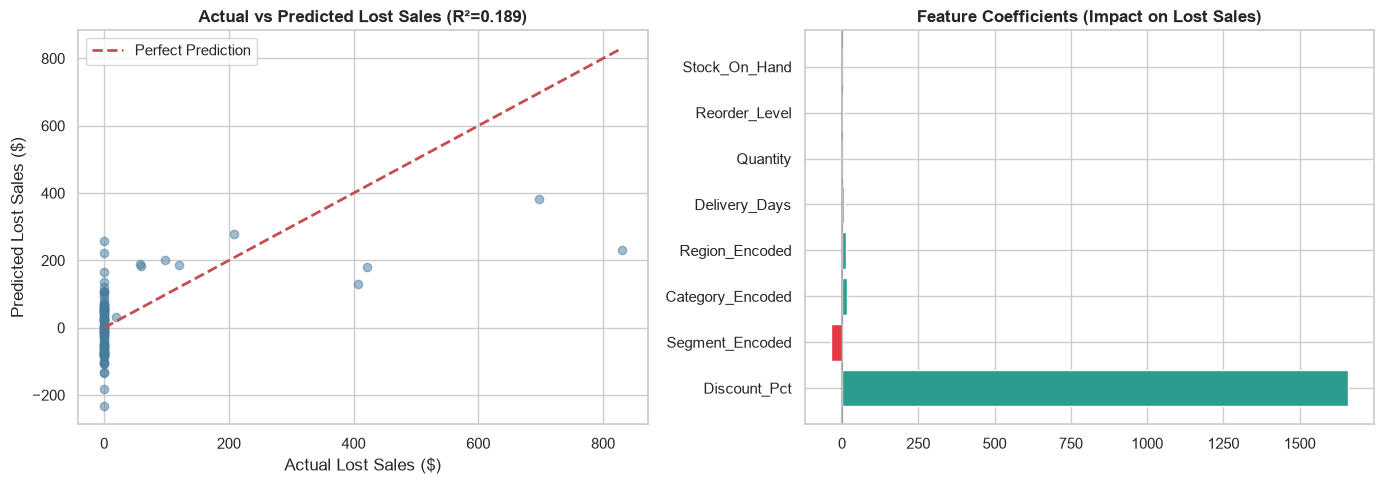

In [5]:
# Prepare features
le_region = LabelEncoder()
le_category = LabelEncoder()
le_segment = LabelEncoder()

model_df = df.copy()
model_df['Region_Encoded'] = le_region.fit_transform(model_df['Region'])
model_df['Category_Encoded'] = le_category.fit_transform(model_df['Product_Category'])
model_df['Segment_Encoded'] = le_segment.fit_transform(model_df['Customer_Segment'])

features = ['Quantity', 'Discount_Pct', 'Delivery_Days', 'Stock_On_Hand',
            'Reorder_Level', 'Region_Encoded', 'Category_Encoded', 'Segment_Encoded']
target = 'Lost_Sales_Estimate'

X = model_df[features]
y = model_df[target]

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit model
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Evaluation
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print('🤖 LINEAR REGRESSION: Predicting Lost Sales')
print('=' * 50)
print(f'R² Score:            {r2:.4f}')
print(f'Mean Absolute Error: ${mae:,.2f}')
print(f'RMSE:                ${rmse:,.2f}')

# Feature importance
importance = pd.DataFrame({
    'Feature': features,
    'Coefficient': model.coef_
}).assign(Abs_Importance=lambda x: x['Coefficient'].abs()).sort_values('Abs_Importance', ascending=False)

print(f'\n📊 Feature Importance (by coefficient magnitude):')
display(importance[['Feature', 'Coefficient']].round(4))

# Actual vs Predicted plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred, alpha=0.5, color='#457B9D')
axes[0].plot([0, y_test.max()], [0, y_test.max()], 'r--', linewidth=2, label='Perfect Prediction')
axes[0].set_title(f'Actual vs Predicted Lost Sales (R²={r2:.3f})', fontweight='bold')
axes[0].set_xlabel('Actual Lost Sales ($)')
axes[0].set_ylabel('Predicted Lost Sales ($)')
axes[0].legend()

# Feature importance bar chart
colors = ['#E63946' if c < 0 else '#2A9D8F' for c in importance['Coefficient']]
axes[1].barh(importance['Feature'], importance['Coefficient'], color=colors, edgecolor='white')
axes[1].set_title('Feature Coefficients (Impact on Lost Sales)', fontweight='bold')
axes[1].axvline(x=0, color='gray', linestyle='-', alpha=0.5)

plt.tight_layout()
plt.savefig('../reports/figures/regression_results.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Test 5: Time Series Decomposition — Revenue Seasonality

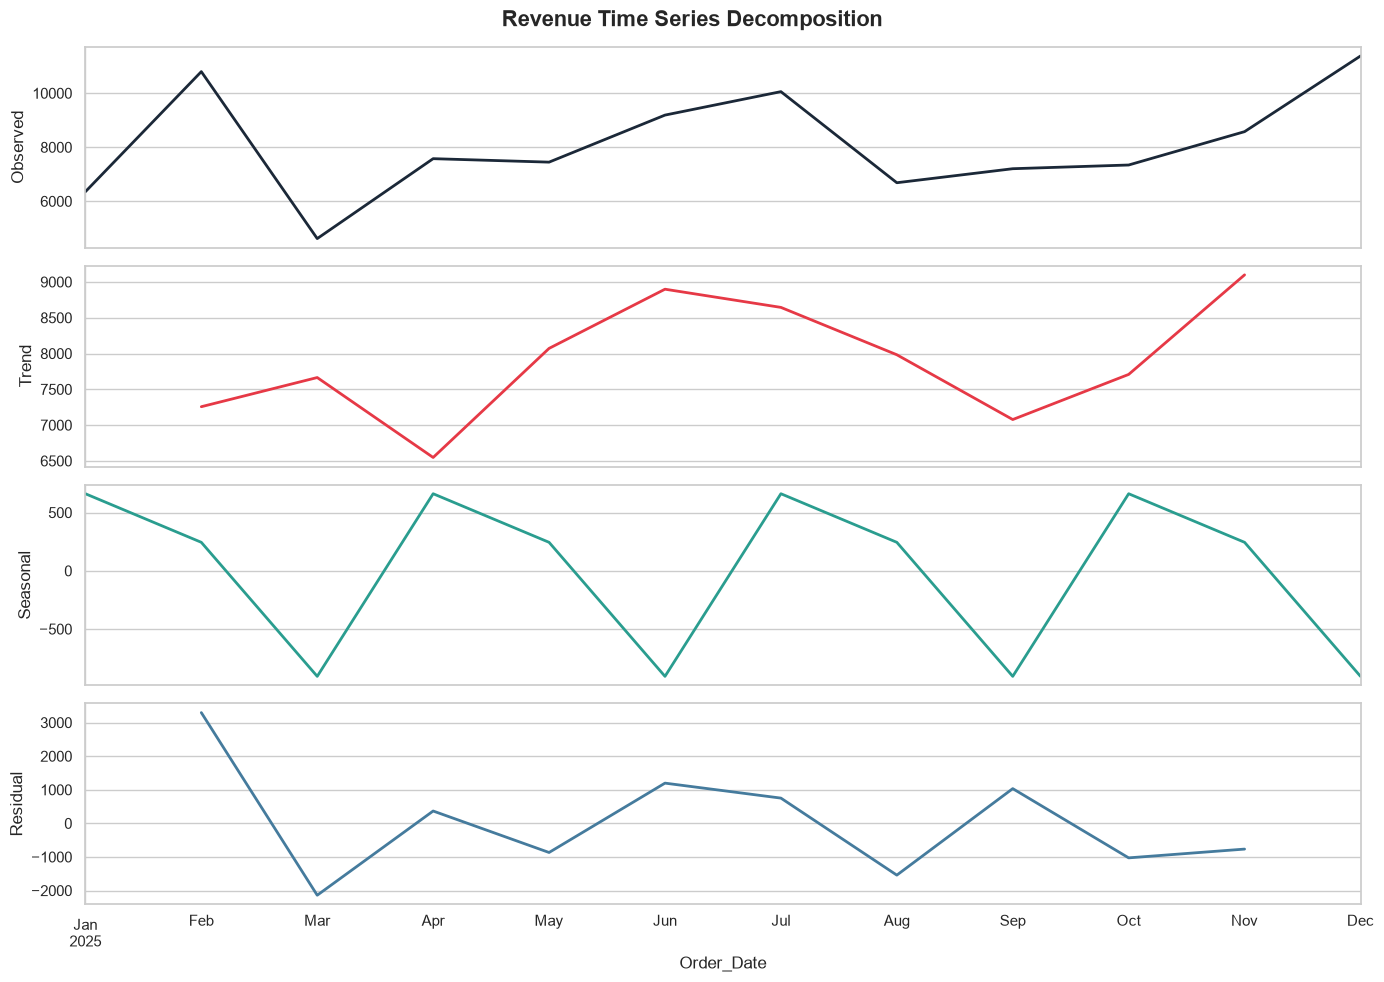

💡 Interpretation:
  - TREND: Shows the underlying revenue direction over 2025
  - SEASONAL: Reveals recurring patterns (quarterly cycles)
  - RESIDUAL: Unexplained variation — spikes may indicate anomalies


In [6]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Aggregate to monthly revenue
monthly_rev = (df.groupby(df['Order_Date'].dt.to_period('M'))['Net_Sales'].sum()
               .reset_index())
monthly_rev['Order_Date'] = monthly_rev['Order_Date'].dt.to_timestamp()
monthly_rev = monthly_rev.set_index('Order_Date')

# Decompose (multiplicative since revenue has proportional seasonality)
try:
    decomposition = seasonal_decompose(monthly_rev['Net_Sales'], model='additive', period=3)
    
    fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
    fig.suptitle('Revenue Time Series Decomposition', fontsize=16, fontweight='bold')
    
    decomposition.observed.plot(ax=axes[0], color='#1B2838', linewidth=2)
    axes[0].set_ylabel('Observed')
    axes[0].set_title('')
    
    decomposition.trend.plot(ax=axes[1], color='#E63946', linewidth=2)
    axes[1].set_ylabel('Trend')
    axes[1].set_title('')
    
    decomposition.seasonal.plot(ax=axes[2], color='#2A9D8F', linewidth=2)
    axes[2].set_ylabel('Seasonal')
    axes[2].set_title('')
    
    decomposition.resid.plot(ax=axes[3], color='#457B9D', linewidth=2)
    axes[3].set_ylabel('Residual')
    axes[3].set_title('')
    
    plt.tight_layout()
    plt.savefig('../reports/figures/time_series_decomposition.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print('💡 Interpretation:')
    print('  - TREND: Shows the underlying revenue direction over 2025')
    print('  - SEASONAL: Reveals recurring patterns (quarterly cycles)')
    print('  - RESIDUAL: Unexplained variation — spikes may indicate anomalies')
except Exception as e:
    print(f'Note: Decomposition requires statsmodels. Install with: pip install statsmodels')
    print(f'Error: {e}')

---
## Summary of Statistical Findings

| Test | Hypothesis | Result | Business Implication |
|------|-----------|--------|---------------------|
| **ANOVA** | Delivery days equal across regions | See output above | Targeted logistics intervention needed |
| **Chi-Square** | Late delivery independent of category | See output above | Category-specific delivery strategies |
| **Pearson** | Discount erodes margins | See output above | Discount policy optimization |
| **Regression** | Predict lost sales | See R² above | Proactive stockout prevention |
| **Time Series** | Revenue seasonality | See decomposition | Inventory planning for peak periods |